... to the only wise God - TTOWG

# Data Manipulation with Pandas

**Learning Outcomes**

At the end of this week, learners should be able to:

+ **Ingest** and inspect petroleum datasets;
+ **Execute** data type conversions;
+ **Navigate** and subset DataFrames;
+ **Perform** domain-specific feature engineering;
+ **Conduct** statistical data aggregation;
+ **Consolidate** disparate data sources;
+ **Remediate** missing sensor data

### Import Libraries

First, we import the essential libraries from the Python Data Science Ecosystem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for subsurface data
#plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

### Data Ingestion & Handling Messy Data

#### Loading Data

The first step in any project is loading data to memory. We use the Pandas library, which represents data in a "DataFrame" (similar to an Excel spreadsheet). We use the pd.read_csv() function to load our comma-separated files.

In [19]:
# Load data from CSV file
daily_prod_data = pd.read_csv('Volve daily production data.csv')


#### Overviewing data

Use .info() to see column names, non-null counts, and data types

In [20]:
daily_prod_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15634 entries, 0 to 15633
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   DATEPRD                   15634 non-null  object 
 1   WELL_BORE_CODE            15634 non-null  object 
 2   NPD_WELL_BORE_CODE        15634 non-null  int64  
 3   NPD_WELL_BORE_NAME        15634 non-null  object 
 4   NPD_FIELD_CODE            15634 non-null  int64  
 5   NPD_FIELD_NAME            15634 non-null  object 
 6   NPD_FACILITY_CODE         15634 non-null  int64  
 7   ON_STREAM_HRS             15349 non-null  float64
 8   AVG_DOWNHOLE_PRESSURE     8980 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  8980 non-null   float64
 10  AVG_DP_TUBING             8980 non-null   float64
 11  AVG_ANNULUS_PRESS         7890 non-null   float64
 12  AVG_CHOKE_SIZE_P          8919 non-null   float64
 13  AVG_CHOKE_UOM             9161 non-null   object 
 14  AVG_WH

In [21]:
cols_to_clean = ['BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL', 'BORE_WI_VOL']

for col in cols_to_clean:
    daily_prod_data[col] = daily_prod_data[col].astype(str).str.replace(',', '').replace('NULL', np.nan).astype(float)
    
daily_prod_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15634 entries, 0 to 15633
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   DATEPRD                   15634 non-null  object 
 1   WELL_BORE_CODE            15634 non-null  object 
 2   NPD_WELL_BORE_CODE        15634 non-null  int64  
 3   NPD_WELL_BORE_NAME        15634 non-null  object 
 4   NPD_FIELD_CODE            15634 non-null  int64  
 5   NPD_FIELD_NAME            15634 non-null  object 
 6   NPD_FACILITY_CODE         15634 non-null  int64  
 7   ON_STREAM_HRS             15349 non-null  float64
 8   AVG_DOWNHOLE_PRESSURE     8980 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  8980 non-null   float64
 10  AVG_DP_TUBING             8980 non-null   float64
 11  AVG_ANNULUS_PRESS         7890 non-null   float64
 12  AVG_CHOKE_SIZE_P          8919 non-null   float64
 13  AVG_CHOKE_UOM             9161 non-null   object 
 14  AVG_WH

#### Parsing Date-time data

By default, Pandas often imports dates as "Objects" (simple strings). To perform time-based operations—like calculating the time between two events, sorting chronologically, or plotting a production decline curve, we must convert these strings into proper _datetime64_ objects.

In [22]:
# Converting the DATEPRD column from a string to a Datetime object
# 'dayfirst=True' is used because the CSV format is DD-Mon-YY

daily_prod_data['DATEPRD'] = pd.to_datetime(daily_prod_data['DATEPRD'], dayfirst=True)

# Confirming the conversion: the dtype for DATEPRD should now be datetime64[ns]
print(daily_prod_data['DATEPRD'].dtype)

C:\Users\HP\AppData\Local\Temp\ipykernel_8396\2023467936.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  daily_prod_data['DATEPRD'] = pd.to_datetime(daily_prod_data['DATEPRD'], dayfirst=True)


datetime64[ns]


#### Handling non-standard formats - montly production data

In [2]:

monthly_prod_data = pd.read_csv('Volve monthly production data.csv')

monthly_prod_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527 entries, 0 to 526
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Wellbore name  526 non-null    object 
 1   NPDCode        526 non-null    float64
 2   Year           526 non-null    float64
 3   Month          526 non-null    float64
 4   On Stream      516 non-null    object 
 5   Oil            312 non-null    object 
 6   Gas            312 non-null    object 
 7   Water          312 non-null    object 
 8   GI             1 non-null      object 
 9   WI             202 non-null    object 
dtypes: float64(3), object(7)
memory usage: 41.3+ KB


Notice how pandas thinks the _On Stream_, _Oil_, _Gas_, _Water_, _GI_ and _WI_ columns are textual data (strings). That's because the dataset includes a "units" row (e.g., Sm3, hrs) immediately below the headers. We skip the second row to ensure our data remains numerical.

In [3]:
# Skip the units row (index 1) to keep the data clean
monthly_prod_data = pd.read_csv('Volve monthly production data.csv' , skiprows=[1])

monthly_prod_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 526 entries, 0 to 525
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Wellbore name  526 non-null    object 
 1   NPDCode        526 non-null    int64  
 2   Year           526 non-null    int64  
 3   Month          526 non-null    int64  
 4   On Stream      515 non-null    float64
 5   Oil            311 non-null    object 
 6   Gas            311 non-null    object 
 7   Water          311 non-null    object 
 8   GI             0 non-null      float64
 9   WI             201 non-null    object 
dtypes: float64(2), int64(3), object(5)
memory usage: 41.2+ KB


### Data cleaning

Unexpectedly, the _Oil_, _Gas_, _Water_ columns are still seen as string objects - that's because of the comma characters used as thousand-separators (e.g., "11,142").

We must strip the commas and convert the strings to floats to perform calculations.

In [4]:

cols_to_clean = ['Oil', 'Gas', 'Water']
for col in cols_to_clean:
    monthly_prod_data[col] = monthly_prod_data[col].astype(str).str.replace(',', '').replace('NULL', np.nan).astype(float)

monthly_prod_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 526 entries, 0 to 525
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Wellbore name  526 non-null    object 
 1   NPDCode        526 non-null    int64  
 2   Year           526 non-null    int64  
 3   Month          526 non-null    int64  
 4   On Stream      515 non-null    float64
 5   Oil            311 non-null    float64
 6   Gas            311 non-null    float64
 7   Water          311 non-null    float64
 8   GI             0 non-null      float64
 9   WI             201 non-null    object 
dtypes: float64(5), int64(3), object(2)
memory usage: 41.2+ KB


### Previewing data

We can get a quick preview of the data: top or bottom rows

In [9]:
daily_prod_data.head(5)

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,0.0,0.000,0.000,...,%,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,0.0,310.376,96.876,...,%,33.098,10.48,33.072,0.0,0.0,0.0,NaN,production,OP


In [10]:
daily_prod_data.tail()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
15629,2016-09-14,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.078,0.229,0.019,0.0,0.0,0.0,NaN,production,OP
15630,2016-09-15,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.085,0.229,0.006,0.0,0.0,0.0,NaN,production,OP
15631,2016-09-16,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.085,0.229,0.012,0.0,0.0,0.0,NaN,production,OP
15632,2016-09-17,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,0.0,NaN,NaN,...,%,0.075,0.228,0.026,0.0,0.0,0.0,NaN,production,OP
15633,2016-09-18,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,0.0,NaN,NaN,...,NaN,NaN,NaN,0.000,NaN,NaN,NaN,0.0,injection,WI


In [5]:
monthly_prod_data.head()

,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI
0,15/9-F-1 C,7405,2014,4,228.0,11142.0,1597937.0,0.0,NaN,NaN
1,15/9-F-1 C,7405,2014,5,734.0,24902.0,3496230.0,783.0,NaN,NaN
2,15/9-F-1 C,7405,2014,6,706.0,19618.0,2886662.0,2068.0,NaN,NaN
3,15/9-F-1 C,7405,2014,7,742.0,15086.0,2249366.0,6244.0,NaN,NaN
4,15/9-F-1 C,7405,2014,8,433.0,6970.0,1048191.0,4530.0,NaN,NaN


In [12]:
monthly_prod_data.tail()

,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI
521,15/9-F-5,5769,2016,5,732.0,9724.0,1534677.0,3950.0,NaN,0
522,15/9-F-5,5769,2016,6,718.0,9121.0,1468557.0,2377.0,NaN,NaN
523,15/9-F-5,5769,2016,7,669.0,9985.0,1602674.0,2454.0,NaN,0
524,15/9-F-5,5769,2016,8,608.0,8929.0,1417279.0,2372.0,NaN,0
525,15/9-F-5,5769,2016,9,0.0,0.0,0.0,0.0,NaN,0


### Data indexing and selection

To analyze data, we must be able to extract exactly what we need from the whole. Pandas provides three primary ways to do this.

#### Selecting columns with square brackets

This is the most direct way to select a specific feature (column). It returns a pandas _series_.

In [23]:
# Select a single column
oil_prod = daily_prod_data['BORE_OIL_VOL']

display(oil_prod.head())

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: BORE_OIL_VOL, dtype: float64

We can select multiple columns by passing a list of column names.

In [14]:
# Select multiple columns
oil_data = daily_prod_data[['DATEPRD', 'NPD_WELL_BORE_NAME', 'BORE_OIL_VOL']]

display(oil_data.head())

,DATEPRD,NPD_WELL_BORE_NAME,BORE_OIL_VOL
0,2014-04-07,15/9-F-1 C,0.0
1,2014-04-08,15/9-F-1 C,0.0
2,2014-04-09,15/9-F-1 C,0.0
3,2014-04-10,15/9-F-1 C,0.0
4,2014-04-11,15/9-F-1 C,0.0


#### Row-column indexing: integer-based with .iloc()

By default, pandas dataframe rows and columns are indexed (labels) with integers, starting from 0. So, we can select specific ranges of rows and columns.

In [15]:
# Select the first 5 rows and the first 3 columns
subset = daily_prod_data.iloc[0:5, 0:3]


display(subset)

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE
0,2014-04-07,NO 15/9-F-1 C,7405
1,2014-04-08,NO 15/9-F-1 C,7405
2,2014-04-09,NO 15/9-F-1 C,7405
3,2014-04-10,NO 15/9-F-1 C,7405
4,2014-04-11,NO 15/9-F-1 C,7405


#### Row indexing: label-based with .loc()

If we have set date or well name as the index, we can use .loc() to grab specific ranges.

In [16]:

oil_data.set_index('DATEPRD', inplace=True)

display(oil_data)

,NPD_WELL_BORE_NAME,BORE_OIL_VOL
DATEPRD,,
2014-04-07,15/9-F-1 C,0.0
2014-04-08,15/9-F-1 C,0.0
2014-04-09,15/9-F-1 C,0.0
2014-04-10,15/9-F-1 C,0.0
2014-04-11,15/9-F-1 C,0.0
...,...,...
2016-09-14,15/9-F-5,0.0
2016-09-15,15/9-F-5,0.0
2016-09-16,15/9-F-5,0.0


In [17]:
oil_data.sort_index(inplace=True)

# Select all data from a specific month in 2008

# .loc[start_label : end_label]


may_2008 = oil_data.loc['2008-05-01':'2008-05-31']

display(may_2008)

C:\Users\HP\AppData\Local\Temp\ipykernel_15012\1473772076.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oil_data.sort_index(inplace=True)


,NPD_WELL_BORE_NAME,BORE_OIL_VOL
DATEPRD,,
2008-05-01,15/9-F-14,0.0
2008-05-01,15/9-F-12,3168.0
2008-05-01,15/9-F-4,NaN
2008-05-01,15/9-F-5,NaN
2008-05-02,15/9-F-14,0.0
...,...,...
2008-05-30,15/9-F-4,NaN
2008-05-31,15/9-F-14,0.0
2008-05-31,15/9-F-4,NaN


#### Boolean indexing (filtering) data

This is how we ask questions of our data. By passing a condition inside the brackets, Pandas returns only the rows where that condition is True

In a multi-well field like Volve, we rarely want to look at all wells at once. We use Boolean Indexing to create subsets of data for specific wells or conditions.

In [24]:
# There may be need to standardize well bore names, if different formats are used
# daily_prod_data['NPD_WELL_BORE_NAME'] = daily_prod_data['NPD_WELL_BORE_NAME'].str.lower()

#  Subset for Well F-12 only
well_12 = daily_prod_data[daily_prod_data['NPD_WELL_BORE_NAME'] == '15/9-F-12'].copy()



# Filter for 'Active Production' days (where the well was on stream for > 20 hours)
active_prod = well_12[well_12['ON_STREAM_HRS'] > 20]

print(f"Total days for F-12: {len(well_12)}")
print(f"Actual producing days: {len(active_prod)}")

Total days for F-12: 3056
Actual producing days: 2634


In [19]:
# Find all days where the well was actually flowing (On Stream > 0)
flowing_days = daily_prod_data[daily_prod_data['ON_STREAM_HRS'] > 0]

display(flowing_days)

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
14,2014-04-21,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,11.50,301.376,102.676,...,%,96.580,19.197,69.776,0.0,0.0,0.0,NaN,production,OP
15,2014-04-22,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,24.00,289.421,106.353,...,%,107.362,37.939,78.935,631.0,90439.0,0.0,NaN,production,OP
16,2014-04-23,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,24.00,270.240,107.644,...,%,99.187,60.757,70.627,1166.0,165720.0,0.0,NaN,production,OP
17,2014-04-24,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,24.00,262.843,107.869,...,%,94.601,63.047,66.049,1550.0,221707.0,0.0,NaN,production,OP
18,2014-04-25,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,24.00,255.527,107.971,...,%,89.988,64.547,61.405,1249.0,178064.0,0.0,NaN,production,OP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15606,2016-08-22,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,24.00,NaN,NaN,...,%,23.650,57.480,0.120,371.0,57935.0,91.0,NaN,production,OP
15607,2016-08-23,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,24.00,NaN,NaN,...,%,23.728,56.862,0.190,379.0,59120.0,90.0,NaN,production,OP
15608,2016-08-24,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,24.00,NaN,NaN,...,%,23.703,56.249,0.168,377.0,58632.0,91.0,NaN,production,OP
15609,2016-08-25,NO 15/9-F-5 AH,5769,15/9-F-5,3420717,VOLVE,369304,24.00,NaN,NaN,...,%,23.642,57.884,0.102,377.0,59337.0,91.0,NaN,production,OP


### Feature engineering - creating new columns

Data science in oil and gas often requires feature engineering, creating new columns that represent field performance metrics better than raw sensor data.

A common task is calculating the _Water Cut_ (the fraction of produced liquid that is water) and _GOR_ (Gas-Oil Ratio), which are critical for reservoir monitoring.

In [25]:
# Calculate Water Cut: Water / (Oil + Water)
well_12['Water_Cut'] = well_12['BORE_WAT_VOL'] / (well_12['BORE_WAT_VOL'] + well_12['BORE_OIL_VOL'])

# Calculate GOR: Gas / Oil
well_12['GOR'] = well_12['BORE_GAS_VOL'] / well_12['BORE_OIL_VOL']

# Handle division-by-zero errors by filling NaNs with 0
well_12[['Water_Cut', 'GOR']] = well_12[['Water_Cut', 'GOR']].fillna(0)

well_12.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3056 entries, 1911 to 4966
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DATEPRD                   3056 non-null   datetime64[ns]
 1   WELL_BORE_CODE            3056 non-null   object        
 2   NPD_WELL_BORE_CODE        3056 non-null   int64         
 3   NPD_WELL_BORE_NAME        3056 non-null   object        
 4   NPD_FIELD_CODE            3056 non-null   int64         
 5   NPD_FIELD_NAME            3056 non-null   object        
 6   NPD_FACILITY_CODE         3056 non-null   int64         
 7   ON_STREAM_HRS             3056 non-null   float64       
 8   AVG_DOWNHOLE_PRESSURE     3050 non-null   float64       
 9   AVG_DOWNHOLE_TEMPERATURE  3050 non-null   float64       
 10  AVG_DP_TUBING             3050 non-null   float64       
 11  AVG_ANNULUS_PRESS         3043 non-null   float64       
 12  AVG_CHOKE_SIZE_P      

### Data aggregation and statistics

#### Summary statistics with _.describe()_

Before performing modelling tasks on datasets, we use the _.describe()_ method to generate a statistical snapshot of the dataset. This allows us to see the count, mean, standard deviation, and quartiles for every numerical column.

In [21]:
# Generate summary statistics for the Well F-12 subset
well_12_stats = well_12.describe()

# Transposing (.T) often makes it easier to read when you have many columns
display(well_12_stats.T)

,count,mean,min,25%,50%,75%,max,std
DATEPRD,3056,2012-06-04 14:32:40.209423872,2008-02-12 00:00:00,2010-03-24 18:00:00,2012-06-10 12:00:00,2014-08-15 06:00:00,2016-09-17 00:00:00,NaN
NPD_WELL_BORE_CODE,3056.0,5599.0,5599.0,5599.0,5599.0,5599.0,5599.0,0.0
NPD_FIELD_CODE,3056.0,3420717.0,3420717.0,3420717.0,3420717.0,3420717.0,3420717.0,0.0
NPD_FACILITY_CODE,3056.0,369304.0,369304.0,369304.0,369304.0,369304.0,369304.0,0.0
ON_STREAM_HRS,3056.0,21.336489,0.0,24.0,24.0,24.0,25.0,6.88903
AVG_DOWNHOLE_PRESSURE,3050.0,80.729069,0.0,0.0,0.0,239.423,317.701,120.086898
AVG_DOWNHOLE_TEMPERATURE,3050.0,33.292082,0.0,0.0,0.0,106.048,107.508,49.354541
AVG_DP_TUBING,3050.0,84.765923,0.0,32.4545,38.7215,171.19,314.409,72.511536
AVG_ANNULUS_PRESS,3043.0,17.272199,0.0,13.976,18.66,20.8255,30.02,6.396437
AVG_CHOKE_SIZE_P,3012.0,69.254352,0.0,48.894108,70.724595,99.99813,100.0,30.179952


What can we make of the summary statistics?


+ Min/Max: Helps identify outliers or sensor errors (e.g., 0 pressure when the well is on-stream).

+ Mean vs. 50% (Median): If these two values are very different, it indicates the data is skewed (e.g., a few days of extremely high production pulling the average up).

+ Std (Standard Deviation): Shows how much the production fluctuates day-to-day. High deviation might indicate unstable flow.

#### Aggregating data with _groupby()_

The groupby() method is one of the most powerful tools in Pandas for summarizing data across categories (e.g., analyzing performance across multiple wells).

The __Split-Apply-Combine__ uses the groupby() method to __split__ our dataset into smaller groups based on a specific column (like _NPD_WELL_BORE_NAME_), __apply__ a mathematical function to each group (like sum, average or count), and __combine__ the results into a clean summary table.

We calculate the count of data points (to check data density per well) and the sum of oil (to get cumulative production per well).

In [22]:
# Grouping by well name
well_summary = daily_prod_data.groupby('NPD_WELL_BORE_NAME').agg({
    'DATEPRD': 'count',       # Counting available days per well
    'BORE_OIL_VOL': 'sum'     # Calculating total lifetime oil production
})


display(well_summary)

,DATEPRD,BORE_OIL_VOL
NPD_WELL_BORE_NAME,,
15/9-F-1 C,746,177707.0
15/9-F-11,1165,1147860.0
15/9-F-12,3056,4579620.0
15/9-F-14,3056,3942270.0
15/9-F-15 D,978,148520.0
15/9-F-4,3327,0.0
15/9-F-5,3306,41163.0


We can rename the columns of the *well_summary* dataframe, for clarity.

In [23]:
# Renaming columns
well_summary.rename(columns={'DATEPRD': 'Total_Days', 'BORE_OIL_VOL': 'Cumulative_Oil'}, inplace=True)


display(well_summary)

,Total_Days,Cumulative_Oil
NPD_WELL_BORE_NAME,,
15/9-F-1 C,746,177707.0
15/9-F-11,1165,1147860.0
15/9-F-12,3056,4579620.0
15/9-F-14,3056,3942270.0
15/9-F-15 D,978,148520.0
15/9-F-4,3327,0.0
15/9-F-5,3306,41163.0


Finally, we can sort the *well_summary* by Cumulative Oil to see the top-producing wells

In [24]:
# Sorting 
well_summary = well_summary.sort_values(by='Cumulative_Oil', ascending=False)

In [25]:
display(well_summary)

,Total_Days,Cumulative_Oil
NPD_WELL_BORE_NAME,,
15/9-F-12,3056,4579620.0
15/9-F-14,3056,3942270.0
15/9-F-11,1165,1147860.0
15/9-F-1 C,746,177707.0
15/9-F-15 D,978,148520.0
15/9-F-5,3306,41163.0
15/9-F-4,3327,0.0


Alternatively, If we need multiple aggregation metrics for a specific column, we can subset the desired column and chain the aggregation operations.

In [26]:
# Calculating count, sum, and mean in one pass
oil_prod_stats = daily_prod_data.groupby('NPD_WELL_BORE_NAME')['BORE_OIL_VOL'].agg(['count', 'sum', 'mean'])

display(oil_prod_stats)

,count,sum,mean
NPD_WELL_BORE_NAME,,,
15/9-F-1 C,746,177707.0,238.213137
15/9-F-11,1165,1147860.0,985.287554
15/9-F-12,3056,4579620.0,1498.566754
15/9-F-14,3056,3942270.0,1290.009817
15/9-F-15 D,978,148520.0,151.860941
15/9-F-4,0,0.0,NaN
15/9-F-5,160,41163.0,257.268750


### Data Integration - Combining datasets

Sometimes, we will have data from different wells in separate files; e.g., well log data.

We can combine them thus:

+ Concat: Used to stack data vertically (putting one well's data under another).

+ Merge: Used to join data horizontally (adding new columns from a different file based on a shared key like "Depth").

In [2]:
# Stacking two different well logs vertically
log_well_1 = pd.read_csv('Well_Log_15-9-F-1 C.csv')
log_well_11 = pd.read_csv('Well_Log_15-9-F-11 B.csv')


print(f"Well 1 dataset contains {log_well_1.shape[0]} total depth points.")
print(f"Well 11 dataset contains {log_well_11.shape[0]} total depth points.")

# We combine them into a single 'master_logs' DataFrame
master_logs = pd.concat([log_well_1, log_well_11], axis=0, ignore_index=True)

print(f"Master dataset contains {master_logs.shape[0]} total depth points.")

Well 1 dataset contains 39481 total depth points.
Well 11 dataset contains 45818 total depth points.
Master dataset contains 85299 total depth points.


In [7]:
log_well_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39481 entries, 0 to 39480
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DEPTH     39481 non-null  float64
 1   ABDCQF01  10200 non-null  float64
 2   ABDCQF02  10200 non-null  float64
 3   ABDCQF03  10200 non-null  float64
 4   ABDCQF04  10200 non-null  float64
 5   BS        39481 non-null  float64
 6   CALI      10225 non-null  float64
 7   DRHO      10223 non-null  float64
 8   GR        38835 non-null  float64
 9   NBGRCFM   10589 non-null  float64
 10  NPHI      10103 non-null  float64
 11  PEF       10129 non-null  float64
 12  RACEHM    27285 non-null  float64
 13  RACELM    27285 non-null  float64
 14  RD        38125 non-null  float64
 15  RHOB      10129 non-null  float64
 16  RM        38149 non-null  float64
 17  ROP       38676 non-null  float64
 18  RPCEHM    27285 non-null  float64
 19  RPCELM    27261 non-null  float64
 20  RT        38149 non-null  fl

In [9]:
log_well_11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45818 entries, 0 to 45817
Data columns (total 20 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DEPTH     45818 non-null  float64
 1   ABDCQF01  15195 non-null  float64
 2   ABDCQF02  15195 non-null  float64
 3   ABDCQF03  15195 non-null  float64
 4   ABDCQF04  15195 non-null  float64
 5   BS        45818 non-null  float64
 6   CALI      15543 non-null  float64
 7   DRHO      15538 non-null  float64
 8   GR        45671 non-null  float64
 9   NPHI      15466 non-null  float64
 10  PEF       15492 non-null  float64
 11  RACEHM    21775 non-null  float64
 12  RACELM    21775 non-null  float64
 13  RD        44857 non-null  float64
 14  RHOB      15492 non-null  float64
 15  RM        45074 non-null  float64
 16  ROP       45411 non-null  float64
 17  RPCEHM    21775 non-null  float64
 18  RPCELM    21558 non-null  float64
 19  RT        45074 non-null  float64
dtypes: float64(20)
memory usage:

In [6]:
master_logs.head()

,DEPTH,ABDCQF01,ABDCQF02,ABDCQF03,ABDCQF04,BS,CALI,DRHO,GR,NBGRCFM,...,PEF,RACEHM,RACELM,RD,RHOB,RM,ROP,RPCEHM,RPCELM,RT
0,145.9,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,146.0,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,146.1,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,146.2,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,146.3,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Cleaning data by interpolation

Subsurface sensors often fail, leaving "NaN" (Not a Number) gaps in well logs. Deleting these rows would ruin our depth continuity. Instead, we use Linear Interpolation to bridge small gaps based on the values before and after the missing section.

In [16]:
print(f"NaNs in RT before interpolation: {log_well_1['RT'].isna().sum()}")

# Bridge gaps in the Resistivity (RT) log
# This creates a smooth curve rather than a broken line in our plots
log_well_1['RT_clean'] = log_well_1['RT'].interpolate(method='linear')

print(f"Remaining NaNs in RT after interpolation: {log_well_1['RT_clean'].isna().sum()}")

NaNs in RT before interpolation: 1332
Remaining NaNs in RT after interpolation: 801


In [12]:
log_well_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39481 entries, 0 to 39480
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DEPTH     39481 non-null  float64
 1   ABDCQF01  10200 non-null  float64
 2   ABDCQF02  10200 non-null  float64
 3   ABDCQF03  10200 non-null  float64
 4   ABDCQF04  10200 non-null  float64
 5   BS        39481 non-null  float64
 6   CALI      10225 non-null  float64
 7   DRHO      10223 non-null  float64
 8   GR        38835 non-null  float64
 9   NBGRCFM   10589 non-null  float64
 10  NPHI      10103 non-null  float64
 11  PEF       10129 non-null  float64
 12  RACEHM    27285 non-null  float64
 13  RACELM    27285 non-null  float64
 14  RD        38125 non-null  float64
 15  RHOB      10129 non-null  float64
 16  RM        38149 non-null  float64
 17  ROP       38676 non-null  float64
 18  RPCEHM    27285 non-null  float64
 19  RPCELM    27261 non-null  float64
 20  RT        38149 non-null  fl

### Time-series

####  Data compression - resampling

Real-time drilling data are recorded at very high frequencies (e.g., every 5 seconds). Resampling allows us to change that frequency. For example, we can aggregate 5-second drilling data into 1-minute averages to smooth out sensor noise.

In [17]:
# Load drilling data
drill_data_time = pd.read_csv('Well_15_9_F_9_A_Drilling_Dynamics_Time.csv')


 # Set the TIME as the index (required for resampling)
drill_data_time['TIME'] = pd.to_datetime(drill_data_time['TIME'])
drill_data_time.set_index('TIME', inplace=True)

display(drill_data_time.shape)

# Take the mean of all values within each 60-second (1 min) window
drill_data_time_resampled = drill_data_time[['ROP', 'RPM', 'SWOB']].resample('1min').mean()

display(drill_data_time_resampled.shape)

(30000, 8)

(1754, 3)

#### Noise reduction and smoothing with moving average

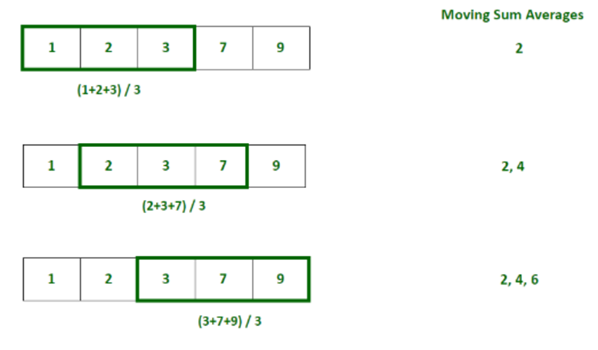


In production data, daily volumes can be extremely noisy due to slugging, sensor issues, or intermittent well testing. Smoothing helps us to distinguish the real decline curve pattern (signal) from the daily operational fluctuations (noise).

Here, we will use a 30-day rolling window, which is standard in the industry to average out weekly operational cycles.

In [35]:
# Apply a 7-day moving average (window=7)
well_12['Oil_30D_Avg'] = well_12['BORE_OIL_VOL'].rolling(window=50).mean()

# This could also be seen as a feature engineering; since a new feature is created.


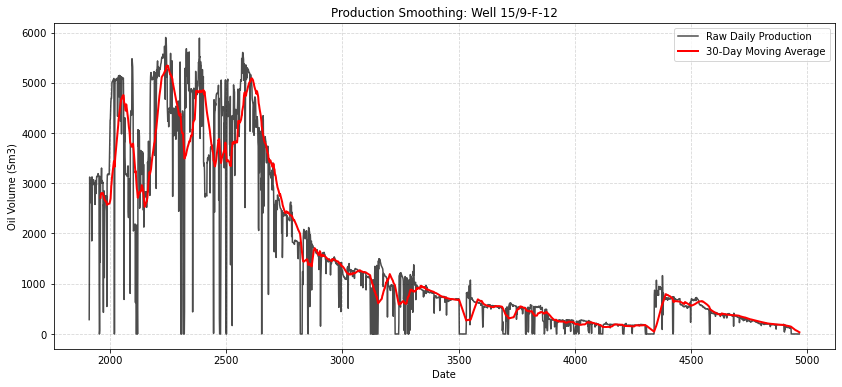

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))


plt.plot(well_12.index.values, well_12['BORE_OIL_VOL'].values, 
         label='Raw Daily Production', alpha=0.7, color='black')

plt.plot(well_12.index.values, well_12['Oil_30D_Avg'].values, 
         label='30-Day Moving Average', color='red', linewidth=2)

plt.title('Production Smoothing: Well 15/9-F-12')
plt.xlabel('Date')
plt.ylabel('Oil Volume (Sm3)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
# plt.show()


In [57]:
well_12[["DATEPRD", "WELL_BORE_CODE", "BORE_OIL_VOL", "Oil_30D_Avg"]].head(35)

,DATEPRD,WELL_BORE_CODE,BORE_OIL_VOL,Oil_30D_Avg
1911,2008-02-12,NO 15/9-F-12 H,285.0,NaN
1912,2008-02-13,NO 15/9-F-12 H,1870.0,NaN
1913,2008-02-14,NO 15/9-F-12 H,3124.0,NaN
1914,2008-02-15,NO 15/9-F-12 H,2608.0,NaN
1915,2008-02-16,NO 15/9-F-12 H,3052.0,NaN
1916,2008-02-17,NO 15/9-F-12 H,2983.0,NaN
1917,2008-02-18,NO 15/9-F-12 H,2981.0,NaN
1918,2008-02-19,NO 15/9-F-12 H,3046.0,NaN
1919,2008-02-20,NO 15/9-F-12 H,3057.0,NaN
1920,2008-02-21,NO 15/9-F-12 H,3030.0,NaN


When we use a 30-day rolling window, the first 29 rows of the new column will be NaN because there are not enough historical data to calculate the moving average. If NaNs are left in the data, they can cause errors in machine learning models.

Here, we will use .dropna() to remove any rows that do not have a valid smoothed value.

In [59]:
# Drop rows where moving average values are missing
well_12_cleaned = well_12.dropna(subset=['Oil_7D_Avg']).copy()

print("\nAfter dropping NaNs:")
print(well_12_cleaned[['BORE_OIL_VOL', 'Oil_7D_Avg']].head())


After dropping NaNs:
      BORE_OIL_VOL   Oil_7D_Avg
1980        2752.0  2682.371429
1981        2737.0  2717.400000
1982        2736.0  2729.771429
1983        2730.0  2724.142857
1984        2728.0  2725.857143


### Reshaping Data

#### Pivoting Tables

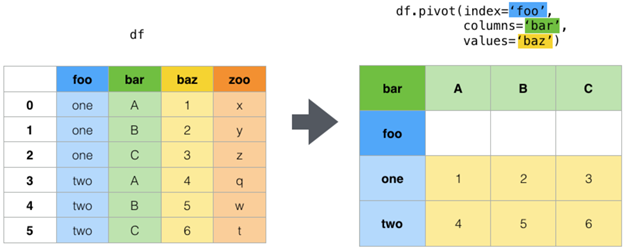

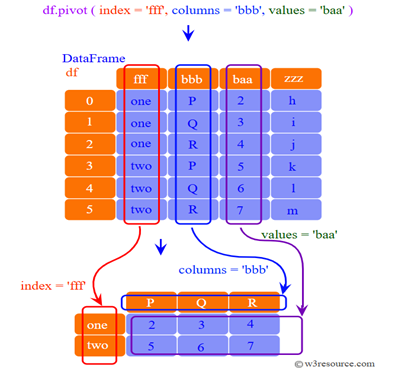

In its raw form, the Volve Monthly Production Data is in "Long" format (one row per well, per month). In the industry, we may need to view the data in its "Wide" format (a table where each column is a different well, each row is a month and the values are the oil volumes). This is essentially creating a summary table, so we can quickly scan across columns to see which well is producing more for a certain month

In [8]:

# Create a 'Date' string for the monthly pproduction data
monthly_prod_data['Period'] = monthly_prod_data['Year'].astype(str) + '-' + monthly_prod_data['Month'].astype(str).str.zfill(2)


monthly_prod_data.head()

,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI,Period
0,15/9-F-1 C,7405,2014,4,228.0,11142.0,1597937.0,0.0,NaN,NaN,2014-04
1,15/9-F-1 C,7405,2014,5,734.0,24902.0,3496230.0,783.0,NaN,NaN,2014-05
2,15/9-F-1 C,7405,2014,6,706.0,19618.0,2886662.0,2068.0,NaN,NaN,2014-06
3,15/9-F-1 C,7405,2014,7,742.0,15086.0,2249366.0,6244.0,NaN,NaN,2014-07
4,15/9-F-1 C,7405,2014,8,433.0,6970.0,1048191.0,4530.0,NaN,NaN,2014-08


In [9]:
monthly_prod_data.tail()

,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI,Period
521,15/9-F-5,5769,2016,5,732.0,9724.0,1534677.0,3950.0,NaN,0,2016-05
522,15/9-F-5,5769,2016,6,718.0,9121.0,1468557.0,2377.0,NaN,NaN,2016-06
523,15/9-F-5,5769,2016,7,669.0,9985.0,1602674.0,2454.0,NaN,0,2016-07
524,15/9-F-5,5769,2016,8,608.0,8929.0,1417279.0,2372.0,NaN,0,2016-08
525,15/9-F-5,5769,2016,9,0.0,0.0,0.0,0.0,NaN,0,2016-09


In [7]:
year = '2024'
month = '8'

period = year+'-'+month

period

'2024-8'

In [14]:
# Pivot: Wells become columns, Periods become rows, Oil is the value
well_comparison = monthly_prod_data.pivot(index='Period', 
                                   columns='Wellbore name', 
                                   values='Oil')

# Display the first few months to see the side-by-side comparison
display(well_comparison.head(10))

Wellbore name,15/9-F-1 C,15/9-F-11,15/9-F-12,15/9-F-14,15/9-F-15 D,15/9-F-4,15/9-F-5
Period,,,,,,,
2007-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-02,NaN,NaN,49091.0,0.0,NaN,NaN,NaN
2008-03,NaN,NaN,83361.0,0.0,NaN,NaN,NaN
2008-04,NaN,NaN,74532.0,0.0,NaN,NaN,NaN
2008-05,NaN,NaN,125479.0,0.0,NaN,NaN,NaN


In [11]:
display(well_comparison.tail(10))

Wellbore name,15/9-F-1 C,15/9-F-11,15/9-F-12,15/9-F-14,15/9-F-15 D,15/9-F-4,15/9-F-5
Period,,,,,,,
2016-03,2918.0,25024.0,7360.0,3754.0,3748.0,NaN,NaN
2016-04,1672.0,13429.0,6152.0,3112.0,4544.0,NaN,3401.0
2016-05,NaN,15529.0,5865.0,3213.0,4699.0,NaN,9724.0
2016-06,NaN,14591.0,5408.0,3075.0,3464.0,NaN,9121.0
2016-07,NaN,14385.0,4534.0,1327.0,829.0,NaN,9985.0
2016-08,NaN,14584.0,1442.0,0.0,0.0,NaN,8929.0
2016-09,NaN,8609.0,0.0,0.0,0.0,NaN,0.0
2016-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN


When we pivoted the monthly production data, we ended up with NaN values for months where a specific well wasn't active. We can use _.fillna()_ to replace the NaNs with 0 (as expected).

In [15]:
# Filling the blanks in the comparison table with zeros
well_comparison = well_comparison.fillna(0)

well_comparison.tail(10)

Wellbore name,15/9-F-1 C,15/9-F-11,15/9-F-12,15/9-F-14,15/9-F-15 D,15/9-F-4,15/9-F-5
Period,,,,,,,
2016-03,2918.0,25024.0,7360.0,3754.0,3748.0,0.0,0.0
2016-04,1672.0,13429.0,6152.0,3112.0,4544.0,0.0,3401.0
2016-05,0.0,15529.0,5865.0,3213.0,4699.0,0.0,9724.0
2016-06,0.0,14591.0,5408.0,3075.0,3464.0,0.0,9121.0
2016-07,0.0,14385.0,4534.0,1327.0,829.0,0.0,9985.0
2016-08,0.0,14584.0,1442.0,0.0,0.0,0.0,8929.0
2016-09,0.0,8609.0,0.0,0.0,0.0,0.0,0.0
2016-10,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2016-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Melting Tables

Melting is the inverse of pivoting.

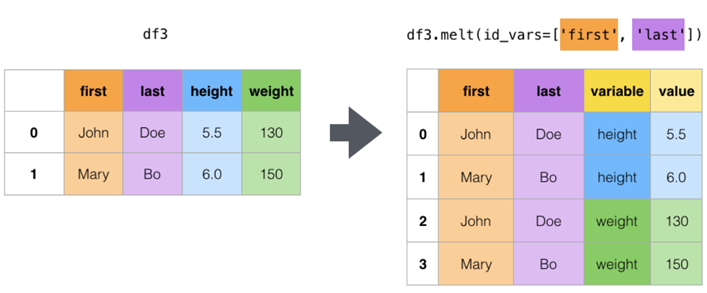

We can take multiple value columns in the monthly production data (Oil, Gas, Water) and melt them into two columns: one for the new attribute name (say "Fluid Type") and the other for the corresponding values, while restoring _Wellbore Name_ and _Period_ as index variables.

**Use Case**: Preparing data for a stacked bar chart where we need one column for the "Fluid Type" (Oil, Gas, Water) to define the colors.

In [81]:
# Select a small subset of the monthly production data
monthly_subset = monthly_prod_data[['Wellbore name', 'Period', 'Oil', 'Water']]

# Melt: Keep Well/Period as identifiers, turn Oil/Gas/Water into a 'Fluid' column
melted_df = pd.melt(monthly_subset, 
                    id_vars=['Wellbore name', 'Period'], 
                    value_vars=['Oil', 'Water'],
                    var_name='Fluid_Type', 
                    value_name='Volume_Sm3')

melted_df.sort_values(by='Period').tail(20)

,Wellbore name,Period,Fluid_Type,Volume_Sm3
166,15/9-F-12,2016-08,Oil,1442.0
524,15/9-F-5,2016-08,Oil,8929.0
525,15/9-F-5,2016-09,Oil,0.0
1051,15/9-F-5,2016-09,Water,0.0
939,15/9-F-4,2016-09,Water,NaN
830,15/9-F-15 D,2016-09,Water,0.0
797,15/9-F-14,2016-09,Water,0.0
693,15/9-F-12,2016-09,Water,0.0
589,15/9-F-11,2016-09,Water,46779.0
63,15/9-F-11,2016-09,Oil,8609.0


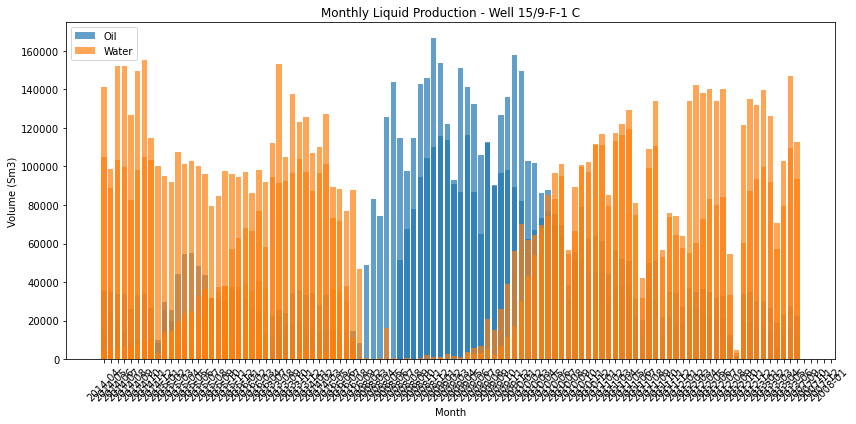

In [82]:
import matplotlib.pyplot as plt
import numpy as np

# Plotting the Melted Data
well_name = '15/9-F-1 C'

fig, ax = plt.subplots(figsize=(12, 6))

# By having a 'Fluid' column, we can easily loop through the categories
for fluid in melted_df['Fluid_Type'].unique():
    subset = melted_df[melted_df['Fluid_Type'] == fluid]
    ax.bar(subset['Period'].values, subset['Volume_Sm3'].values, label=fluid, alpha=0.7)

ax.set_title(f'Monthly Liquid Production - Well {well_name}')
ax.set_xlabel('Month')
ax.set_ylabel('Volume (Sm3)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()